# Car Price Prediction with Machine Learning

Task 3: a reproducible regression analysis using Pandas, Scikit-learn and Matplotlib. This notebook presents the supplied data, preprocessing decisions, model comparison, independent evaluation and example inference. See README.md for setup and REPORT.md for conclusions.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import pandas as pd
import joblib
from IPython.display import display, Image
ROOT = Path.cwd()
assert (ROOT / "train.py").exists(), "Open this notebook from the project directory"
RUN_TRAINING = False
if RUN_TRAINING or not (ROOT / "outputs/metrics.json").exists():
    subprocess.run([sys.executable, str(ROOT / "train.py")], check=True)
out = ROOT / "outputs"

## 1. Inspect the supplied dataset

The archive includes cars and two-wheelers. Prices are kept in dataset units because the supplied archive does not verify currency or source. Manufacturing years extend to 2018; this is a historical exercise.

In [2]:
raw = pd.read_csv(ROOT / "archive (3).zip")
display(raw.head())
display(raw.describe(include="all").T)
display(raw.isna().sum().rename("missing_count").to_frame())
print("Original shape:", raw.shape, "Exact duplicates:", raw.duplicated().sum())

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
Selling_Price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
Present_Price,301.0,NaN,NaN,NaN,7.628472,8.642584,0.32,1.2,6.4,9.9,92.6
Driven_kms,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
Fuel_Type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Selling_type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0


,missing_count
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Driven_kms,0
Fuel_Type,0
Selling_type,0
Transmission,0
Owner,0


Original shape: (301, 9) Exact duplicates: 2


## 2. Clean data and engineer features

Normalize text, remove exact duplicates before splitting, and use an explicit car-model allowlist. This leaves 198 cars. Brand is a categorical proxy, not measured goodwill. Horsepower and fuel economy are unavailable; Driven_kms is odometer distance. Age uses an assumed 2018 snapshot, annual distance divides by at least one year, and log distance compresses its scale. Imputation, scaling and encoding are fitted inside each training fold.

Cars: 198 Excluded two-wheelers/unmapped: 101


,Present_Price,Driven_kms,Owner,Car_Age,Km_Per_Year,Log_Km,Car_Name,Brand,Fuel_Type,Selling_type,Transmission
source_row,,,,,,,,,,,
0,5.59,27000,0,4,6750.000000,10.203629,ritz,Maruti Suzuki,petrol,dealer,manual
1,9.54,43000,0,5,8600.000000,10.668979,sx4,Maruti Suzuki,diesel,dealer,manual
2,9.85,6900,0,1,6900.000000,8.839422,ciaz,Maruti Suzuki,petrol,dealer,manual
3,4.15,5200,0,7,742.857143,8.556606,wagon r,Maruti Suzuki,petrol,dealer,manual
4,6.87,42450,0,4,10612.500000,10.656106,swift,Maruti Suzuki,diesel,dealer,manual


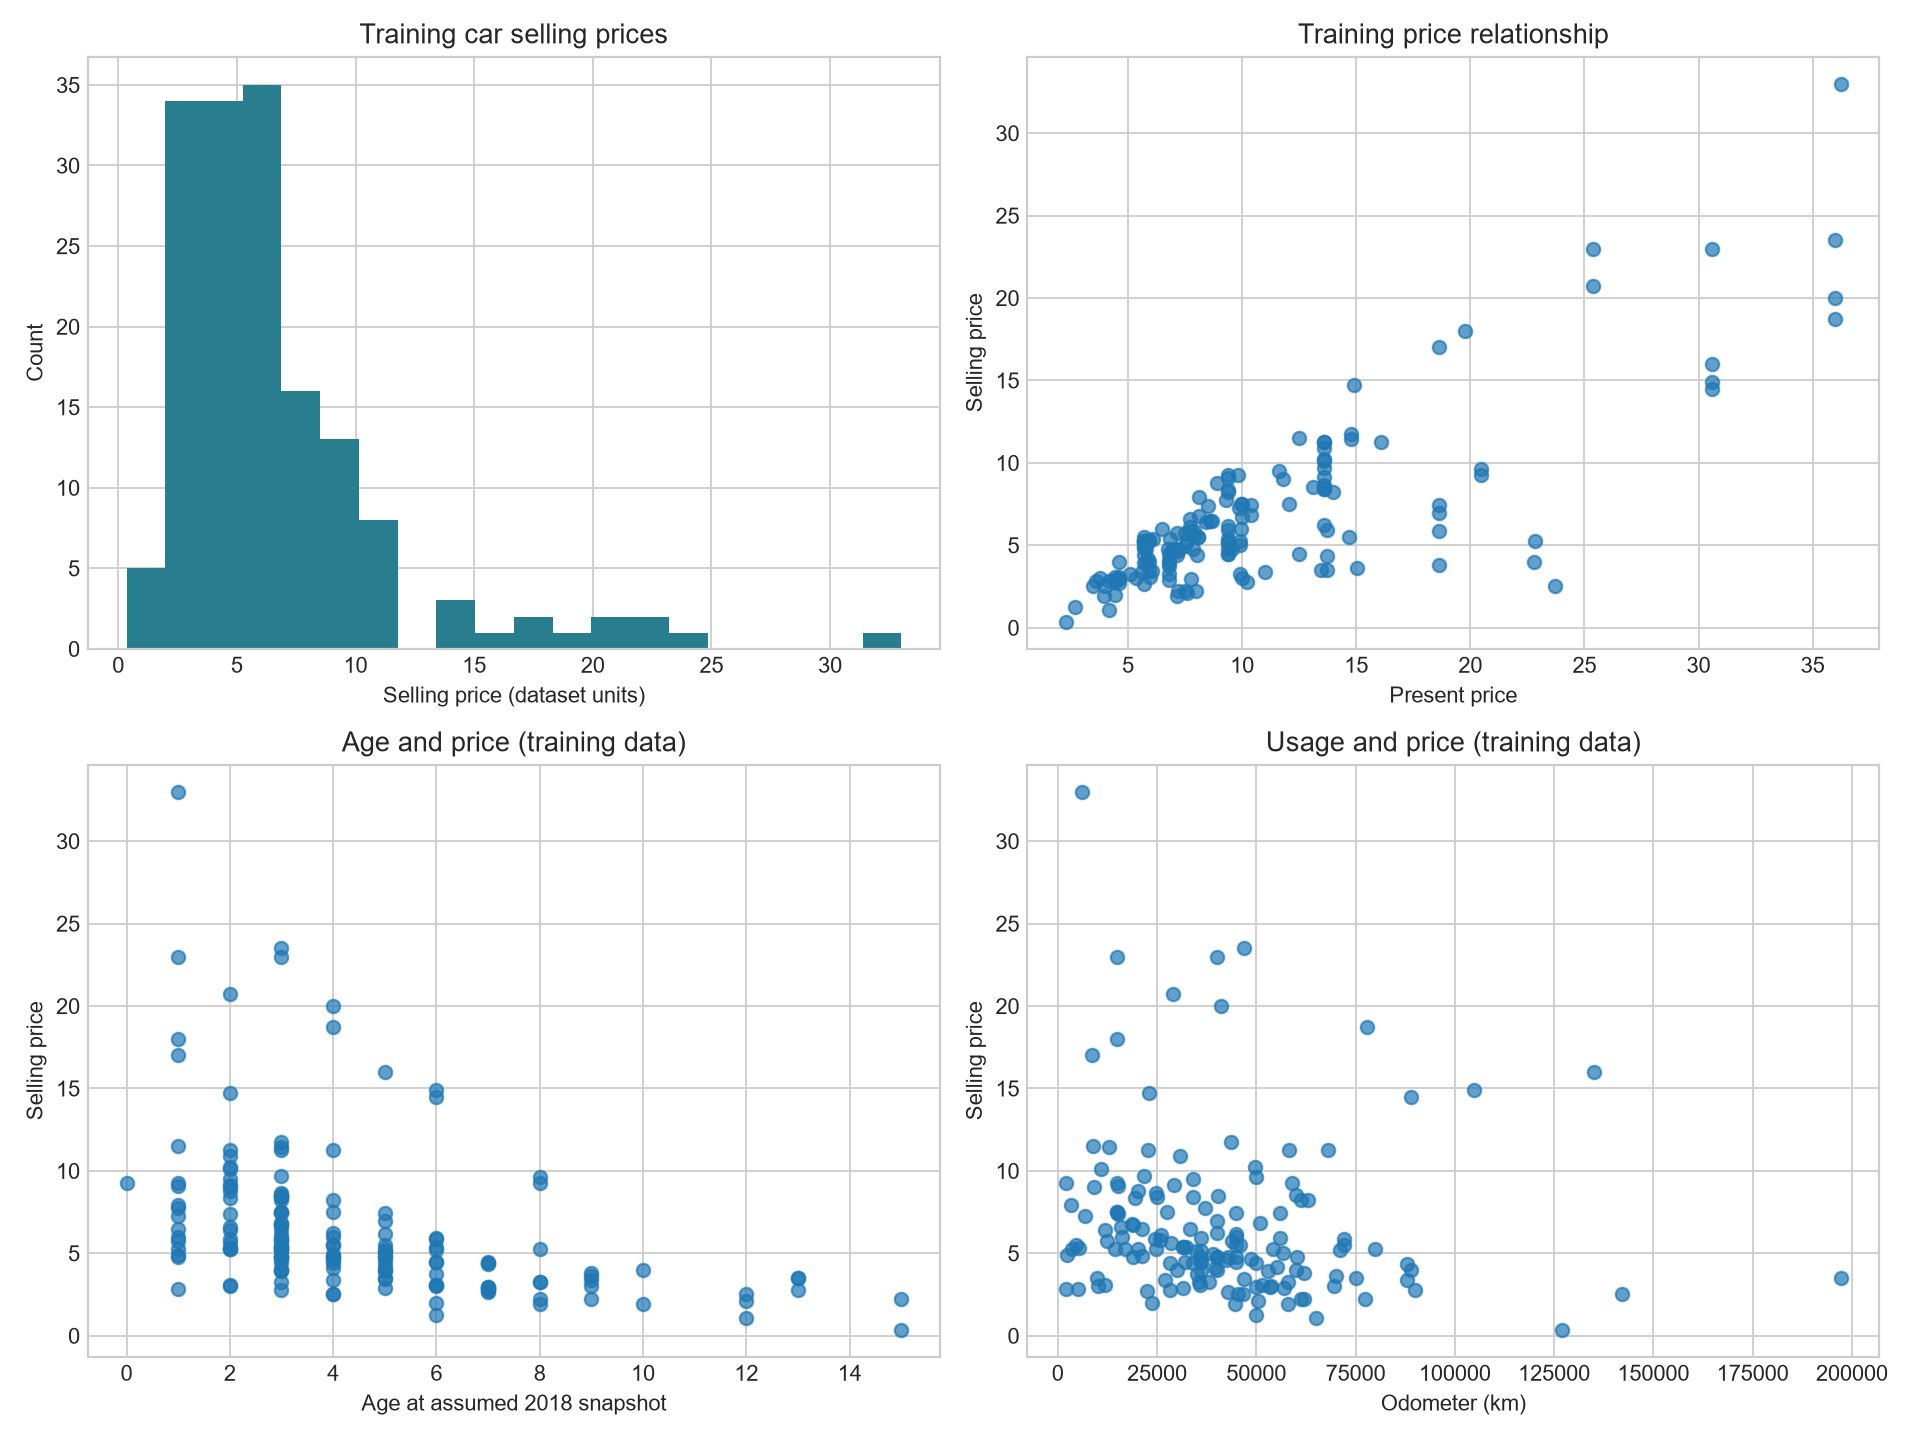

In [3]:
from car_price import FeatureEngineer, RAW_FEATURES
cars = pd.read_csv(out / "cars_cleaned.csv", index_col="source_row")
excluded = pd.read_csv(out / "excluded_non_car_or_unmapped.csv")
print("Cars:", len(cars), "Excluded two-wheelers/unmapped:", len(excluded))
display(FeatureEngineer().fit_transform(cars[RAW_FEATURES]).head())
display(Image(filename=str(out / "exploration.png")))

## 3. Select the model using training data

A reproducible 80/20 split reserves 40 cars. Five-fold shuffled cross-validation on 158 training cars compares a median baseline and four regressor families. Small hyperparameter grids are evaluated by MAE. Model selection never uses the holdout. CV scores after tuning have selection optimism; fold standard deviations are not confidence intervals.

In [4]:
scores = pd.read_csv(out / "cross_validation.csv")
display(scores)
metrics = json.loads((out / "metrics.json").read_text())
print("Selected:", metrics["selected_model"])
print("Parameters:", metrics["best_parameters"])

,model,cv_mae,cv_mae_std,cv_rmse,cv_r2,parameters
0,Gradient boosting,0.731188,0.214936,1.155146,0.939643,"{""model__learning_rate"": 0.05, ""model__max_dep..."
1,Extra trees,0.761759,0.201481,1.174984,0.936723,"{""model__min_samples_leaf"": 1}"
2,Random forest,0.822476,0.182430,1.307430,0.921805,"{""model__max_depth"": null, ""model__min_samples..."
3,Ridge,1.188531,0.266622,1.729859,0.859508,"{""model__alpha"": 10}"
4,Median baseline,3.008145,0.753526,4.802852,-0.089270,{}


Selected: Gradient boosting
Parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}


## 4. Independent holdout evaluation

MAE measures typical absolute error; RMSE emphasizes large misses; R? measures improvement in squared error relative to the holdout mean. Report every holdout record, including difficult luxury cars.

,mae,rmse,r2
training,0.229098,0.300932,0.996087
holdout,1.198452,3.425451,0.652306
baseline_holdout,3.060000,5.913396,-0.036181


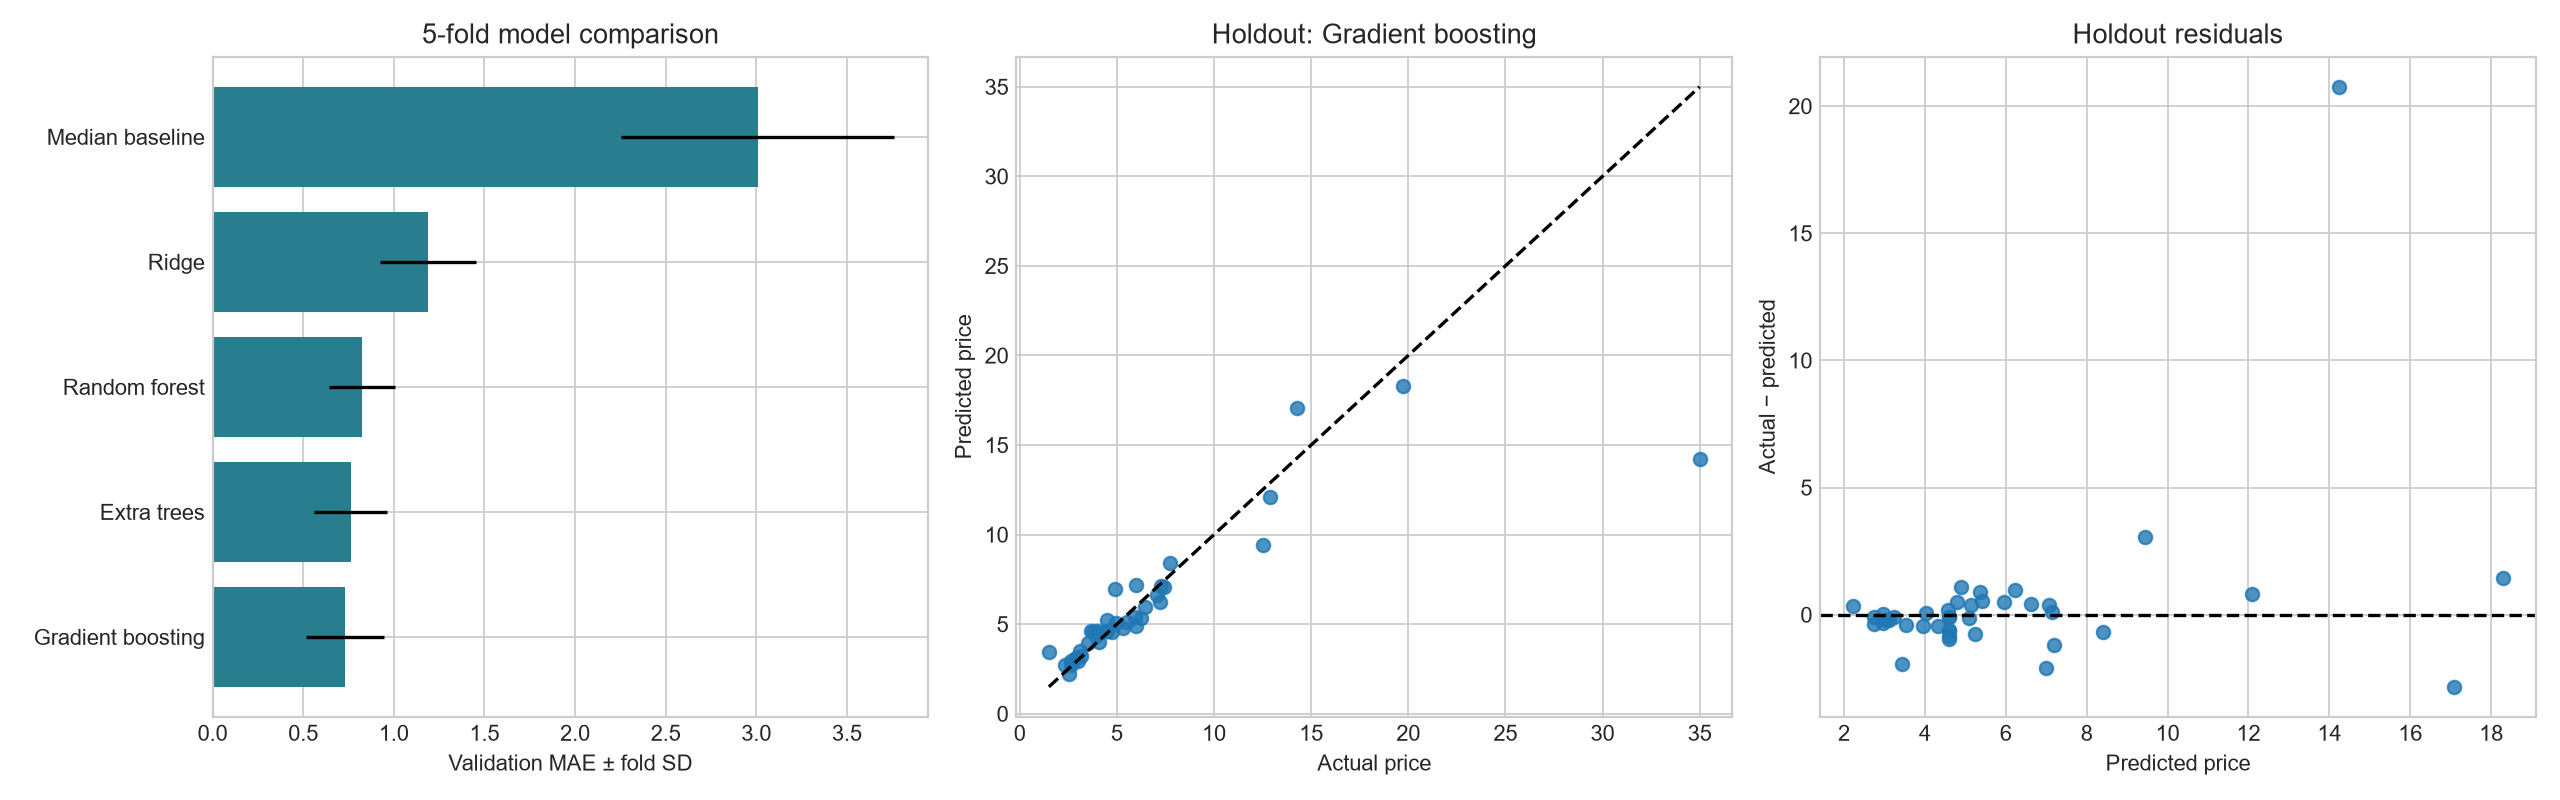

,source_row,Car_Name,Year,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,actual,predicted,residual,absolute_error
19,86,land cruiser,2010,92.60,78000,diesel,dealer,manual,0,35.00,14.240727,20.759273,20.759273
33,83,innova,2015,13.46,38000,diesel,dealer,manual,0,12.50,9.435609,3.064391,3.064391
25,69,corolla altis,2016,20.91,12000,petrol,dealer,manual,0,14.25,17.087455,-2.837455,2.837455
24,74,etios cross,2014,8.93,83000,diesel,dealer,manual,0,4.90,6.982093,-2.082093,2.082093
31,77,corolla,2004,12.35,135154,petrol,dealer,automatic,0,1.50,3.440983,-1.940983,1.940983


In [5]:
display(pd.DataFrame({k: metrics[k] for k in ["training", "holdout", "baseline_holdout"]}).T)
display(Image(filename=str(out / "evaluation.png")))
predictions = pd.read_csv(out / "holdout_predictions.csv")
display(predictions.assign(absolute_error=predictions.residual.abs()).nlargest(5, "absolute_error"))

The holdout MAE is about 1.20 versus baseline 3.06, but R? is only 0.65. The Land Cruiser is severely underpredicted (35.00 actual versus 14.24 predicted). Training MAE of 0.23 and CV MAE of 0.73 are substantially lower than holdout MAE. This shows the limits of a small historical sample and poor extrapolation for rare luxury vehicles. Do not treat the CV R? of 0.94 as final accuracy.

## 5. Interpret model behavior

Permutation importance measures the holdout MAE increase after shuffling a raw feature. Derived features are recomputed, so Year includes age effects and Car_Name includes brand effects. Importance is descriptive, not causal, and correlated inputs can obscure effects.

,feature,mae_increase,std
7,Present_Price,2.820546,0.274113
6,Year,0.870426,0.270070
5,Fuel_Type,0.075964,0.028458
4,Car_Name,0.064107,0.024452
3,Driven_kms,0.025817,0.027627
1,Selling_type,0.000000,0.000000
2,Owner,0.000000,0.000000
0,Transmission,-0.003074,0.011454


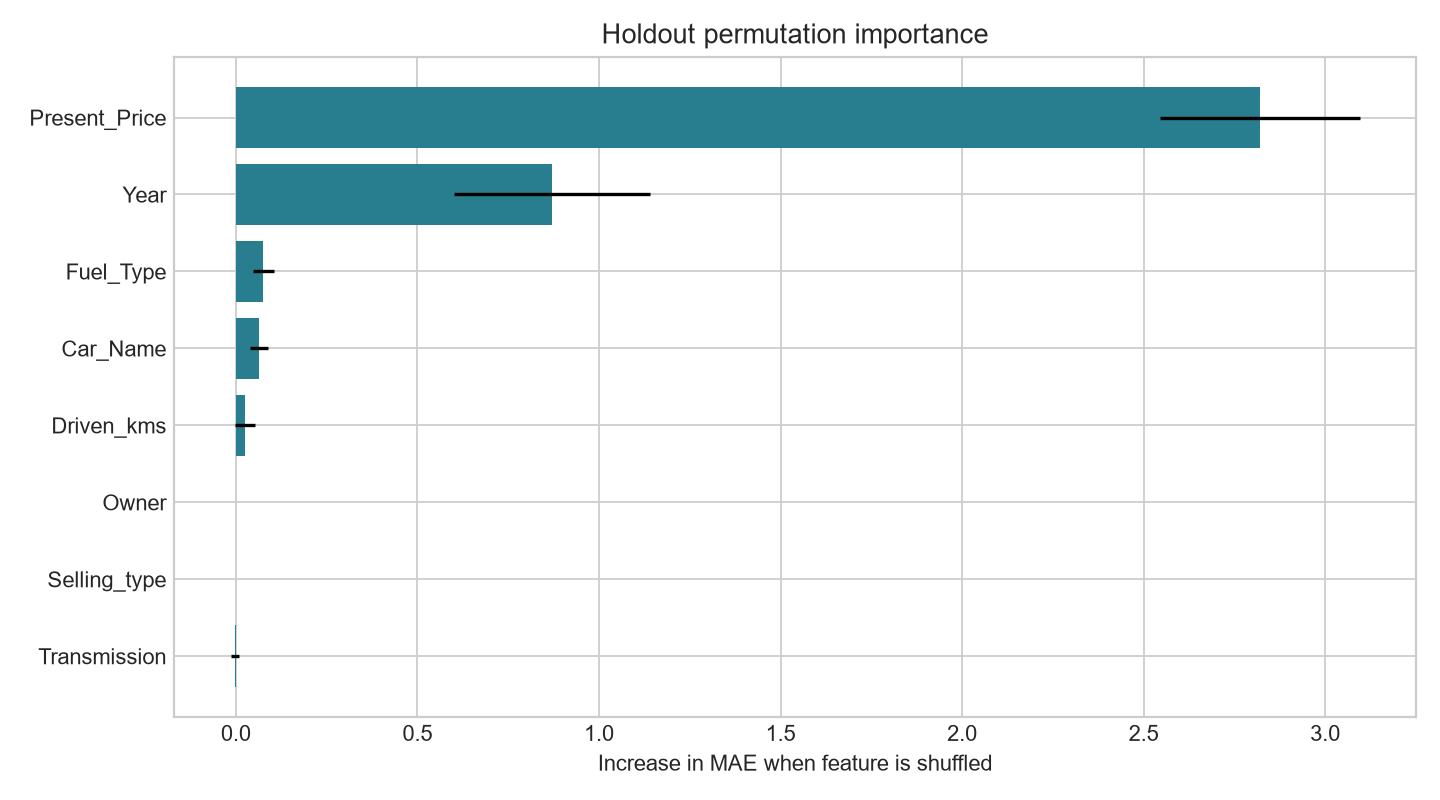

In [6]:
display(pd.read_csv(out / "feature_importance.csv").sort_values("mae_increase", ascending=False))
display(Image(filename=str(out / "feature_importance.png")))

## 6. Predict with the saved pipeline

This artifact is exactly the training-only model evaluated above. Only load trusted joblib files. Use historical inputs in the same units; the CLI rejects unknown models and post-2018 years.

In [7]:
model = joblib.load(out / "car_price_model.joblib")
examples = pd.read_csv(ROOT / "examples/cars.csv")
examples["Predicted_Selling_Price"] = model.predict(examples)
display(examples)

,Car_Name,Year,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Predicted_Selling_Price
0,swift,2015,6.87,35000,Petrol,Dealer,Manual,0,5.043459
1,city,2016,13.60,25000,Petrol,Dealer,Automatic,0,10.026711


## 7. Applications and next steps

Dealer trade-in assistance, marketplace listing recommendations and inventory screening are potential applications after further validation. This model is not suitable for current prices. Collect recent licensed transactions, dates, vehicle identifiers, region, condition, horsepower and verified currency. Validate with temporal and vehicle-group splits, assess rare-brand and luxury errors, calibrate uncertainty and monitor drift. Verify that Present_Price is available at inference time and was not recorded after the sale. The dataset cannot establish causal brand goodwill.

Automated checks cover derived features, missing values, unseen categories and invalid numerical inputs. The following checks also verify the persisted pipeline reproduces holdout predictions and that split row IDs do not overlap.

In [8]:
import numpy as np
np.testing.assert_allclose(model.predict(predictions[RAW_FEATURES]), predictions.predicted, rtol=1e-10)
split = pd.read_csv(out / "split.csv")
assert split.source_row.is_unique
assert len(split) == len(cars)
assert (split["split"] == "test").sum() == len(predictions)
result = subprocess.run([sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"], capture_output=True, text=True)
print(result.stdout + result.stderr)
assert result.returncode == 0
print("Saved-model and split-integrity checks passed.")

test_age_usage_and_brand (test_workflow.WorkflowTests.test_age_usage_and_brand) ... ok
test_invalid_inputs_rejected (test_workflow.WorkflowTests.test_invalid_inputs_rejected) ... ok
test_missing_and_unknown_values (test_workflow.WorkflowTests.test_missing_and_unknown_values) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.076s

OK

Saved-model and split-integrity checks passed.
